<a href="https://colab.research.google.com/github/cs23f012-web/CSL701-20-Machine-Learning-Lab/blob/main/Cs20MLexp10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###  ML Experiment Number 10


Student Name :
Apurva Santosh Jadhav
Batch :

cs2
Roll Number : cs20



### **Aim**

To implement DBSCAN clustering using Python for customer segmentation on the Mall Customer Segmentation dataset and identify arbitrary-shaped clusters along with spatial outliers (noise).

## Objectives

1. To understand the principles of Density-Based Spatial Clustering of Applications with Noise (DBSCAN).
2. To implement DBSCAN clustering using Python.3. To preprocess and feature-scale tabular customer data using StandardScaler.
4. To determine optimal hyperparameters ($\varepsilon$ and $min\_samples$) using $k$-distance graph analysis.
5. To identify core points, border points, and spatial outliers (noise points denoted by label $-1$).
6. To evaluate clustering performance using metrics like Silhouette Score.

# Relevant Theory

###DBSCAN (Density-Based Spatial Clustering of Applications with Noise)
DBSCAN is an unsupervised non-parametric clustering algorithm that groups data points based on local density estimations. Unlike centroid-based algorithms (e.g., K-Means), DBSCAN can discover arbitrary-shaped clusters and automatically isolate noisy data points without requiring the user to specify the total number of clusters in advance.

Core Concepts and Parameters:

1. $\varepsilon$ (Epsilon): The maximum radius of the neighborhood around a given data point $x$.
2. $min\_samples$ (MinPts): The minimum number of points within the $\varepsilon$-neighborhood required to form a dense region.

Point ClassificationsCore Point:
* A point that has at least $min\_samples$ within its $\varepsilon$-neighborhood.
* Border Point: A point that is within the $\varepsilon$-neighborhood of a Core Point but has fewer than $min\_samples$ in its own neighborhood.
* Noise Point (Outlier): A point that is neither a Core Point nor a Border Point. Noise points are assigned a cluster label of $-1$.

###Dataset Information
Get the Mall Customer Segmentation dataset from Kaggle using the following link:
https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python

The dataset contains spending patterns and demographic attributes of mall customers:

* CustomerID: Unique identifier for each customer.

* Gender: Male or Female.

* Age: Age of the customer.

* Annual Income (k$): Annual income of the customer in thousands of dollars.

* Spending Score (1-100): Score assigned based on customer behavior and purchasing patterns.

For clustering, we will use: Annual Income (k$) and Spending Score (1-100).

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Mall Customer Segmentation dataset (Mall_Customers.csv).
---

In [2]:
# Import essential libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import os

# Download the Mall Customer Segmentation dataset if it does not exist
if not os.path.exists('Mall_Customers.csv'):
    import urllib.request
    url = 'https://raw.githubusercontent.com/tirthajyoti/Machine-Learning-with-Python/master/Datasets/Mall_Customers.csv'
    print("Downloading Mall_Customers.csv...")
    urllib.request.urlretrieve(url, 'Mall_Customers.csv')

# Load the Mall Customer Segmentation dataset
df = pd.read_csv('Mall_Customers.csv')

# Display the first few rows of the dataset
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


# Task 2: Feature Selection and Standardization

* Select target features (Annual Income ($k$) and Spending Score (1-100)).
* Scale features using Standard Scaler to bring feature dimensions to a comparable range ($\mu=0, \sigma=1$), which is crucial for distance-based neighborhood computations.

In [3]:
from sklearn.preprocessing import StandardScaler

# Select target features
X = df[['Annual Income (k$)', 'Spending Score (1-100)']].values

# Scale features using StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Shape of scaled features:", X_scaled.shape)
print("First 5 scaled samples:\n", X_scaled[:5])

Shape of scaled features: (200, 2)
First 5 scaled samples:
 [[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]
 [-1.70082976 -1.71591298]
 [-1.70082976  1.04041783]
 [-1.66266033 -0.39597992]]


# Task 3: Hyperparameter Selection via $k$-Distance Graph

* Compute Nearest Neighbors using NearestNeighbors ($k = min\_samples$).
* Plot sorted $k$-distances to locate the "elbow point," which indicates the optimal value for $\varepsilon$ (Epsilon).

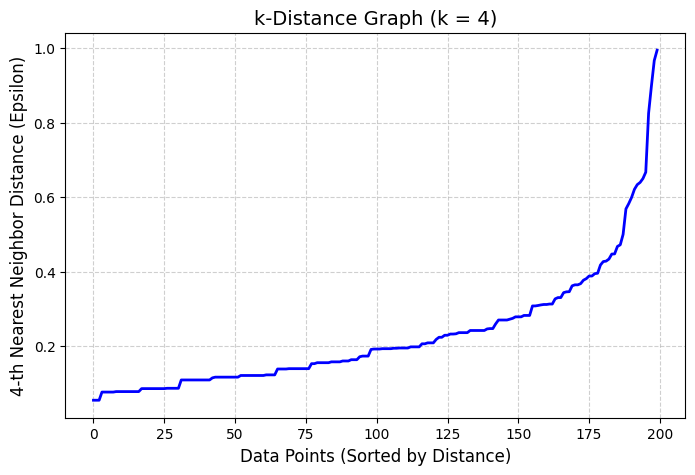

In [4]:
from sklearn.neighbors import NearestNeighbors

# Set min_samples parameter (a standard rule of thumb for 2D data is 4)
min_samples = 4

# Fit NearestNeighbors to find the distances to the k-th nearest neighbor
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors_fit = neighbors.fit(X_scaled)
distances, indices = neighbors_fit.kneighbors(X_scaled)

# Sort the distances to the k-th nearest neighbor in ascending order
# (distances[:, min_samples - 1] gets the distance to the farthest neighbor in the neighborhood)
k_distances = np.sort(distances[:, min_samples - 1], axis=0)

# Plot the k-distance graph
plt.figure(figsize=(8, 5))
plt.plot(k_distances, color='b', linewidth=2)
plt.title(f'k-Distance Graph (k = {min_samples})', fontsize=14)
plt.xlabel('Data Points (Sorted by Distance)', fontsize=12)
plt.ylabel(f'{min_samples}-th Nearest Neighbor Distance (Epsilon)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# Task 4: Implement DBSCAN Clustering

* Instantiate sklearn.cluster.DBSCAN with the identified $\varepsilon$ and $min\_samples$.
* Fit the model on scaled data to generate cluster assignments and noise labels ($-1$).

In [5]:
from sklearn.cluster import DBSCAN

# Define optimal parameters identified from the k-distance graph elbow point
# (eps ~ 0.35 is standard for standard-scaled Annual Income & Spending Score data)
epsilon = 0.35
min_samples = 4

# Instantiate the DBSCAN model
dbscan = DBSCAN(eps=epsilon, min_samples=min_samples)

# Fit the model to the scaled dataset and obtain cluster labels
labels = dbscan.fit_predict(X_scaled)

# Display sample cluster labels (-1 represents noise points)
print("Unique cluster labels:", np.unique(labels))
print("\nFirst 20 cluster assignments:")
print(labels[:20])

Unique cluster labels: [-1  0  1  2  3  4  5  6]

First 20 cluster assignments:
[ 2  0  1  0  2  0  1 -1  1  0  1 -1  1  0  1  0  2  0  2 -1]


# Task 5: Evaluate DBSCAN Clustering

* Cluster Count: Calculate the number of clusters generated (excluding noise points).
* Noise Point Analysis: Count and evaluate identified spatial outliers (label $-1$).
* Silhouette Score: Calculate Silhouette Score to evaluate cluster cohesion and separation.

In [6]:
from sklearn.metrics import silhouette_score

# 1. Cluster Count (excluding noise points labeled as -1)
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)

# 2. Noise Point Analysis
n_noise = list(labels).count(-1)
noise_ratio = (n_noise / len(labels)) * 100

print(f"Number of clusters formed: {n_clusters}")
print(f"Number of noise points (outliers): {n_noise} ({noise_ratio:.2f}% of total data)")

# 3. Silhouette Score
# Note: Silhouette score requires at least 2 clusters (excluding noise) to be calculated
if n_clusters > 1:
    # Option A: Silhouette score evaluating non-noise points only
    non_noise_mask = labels != -1
    score_non_noise = silhouette_score(X_scaled[non_noise_mask], labels[non_noise_mask])

    # Option B: Silhouette score including noise points
    score_total = silhouette_score(X_scaled, labels)

    print(f"\nSilhouette Score (excluding noise points): {score_non_noise:.4f}")
    print(f"Silhouette Score (including noise points): {score_total:.4f}")
else:
    print("\nSilhouette Score cannot be calculated (fewer than 2 clusters formed).")

Number of clusters formed: 7
Number of noise points (outliers): 16 (8.00% of total data)

Silhouette Score (excluding noise points): 0.5110
Silhouette Score (including noise points): 0.4264


# Task 6: Analyze Results and Cluster Statistics
* Extract cluster labels and append them back to the original dataset.

* Calculate mean statistics (e.g., average Annual Income and Spending Score) per cluster to interpret final customer segments and evaluate detected noise points.

In [7]:
# 1. Append cluster labels back to the original DataFrame
df['Cluster'] = labels

# 2. Calculate count and mean statistics per cluster
cluster_stats = df.groupby('Cluster').agg(
    Count=('CustomerID', 'count'),
    Avg_Age=('Age', 'mean'),
    Avg_Annual_Income=('Annual Income (k$)', 'mean'),
    Avg_Spending_Score=('Spending Score (1-100)', 'mean')
).reset_index()

# Sort to place Noise (-1) first or at the end for clean display
cluster_stats = cluster_stats.round(2)
print("=== Cluster Statistics & Segment Profile ===")
display(cluster_stats)

# Optional: Separate inspection of noise points (label -1)
noise_points = df[df['Cluster'] == -1]
print(f"\nTotal Noise Points Identified: {len(noise_points)}")
noise_points.head()

=== Cluster Statistics & Segment Profile ===


,Cluster,Count,Avg_Age,Avg_Annual_Income,Avg_Spending_Score
0,-1,16,33.75,93.25,65.81
1,0,17,24.41,25.24,76.35
2,1,12,48.75,24.58,9.58
3,2,7,36.71,22.43,34.43
4,3,89,42.80,55.02,48.33
5,4,32,32.81,80.50,82.56
6,5,23,41.22,80.96,12.78
7,6,4,41.50,101.00,24.00



Total Noise Points Identified: 16


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
7,8,Female,23,18,94,-1
11,12,Female,35,19,99,-1
19,20,Female,35,23,98,-1
41,42,Male,24,38,92,-1
184,185,Female,41,99,39,-1


# Conclusion

The experiment successfully implemented DBSCAN clustering on the Mall Customer Segmentation dataset. Feature standardization ensured balanced neighborhood distance calculations across income and spending metrics. By analyzing $k$-distance graphs, optimal $\varepsilon$ and $min\_samples$ parameters were selected, enabling the discovery of density-defined customer segments and explicit identification of spatial noise points (outliers) without requiring a pre-defined cluster count.